# Tesco grocery purchasing patterns

Product preferences and seasonal and geographical purchasing patterns across London in 2015.

In [1]:
import pandas as pd
import json

import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns

## Load data

Source: [Tesco Grocery 1.0](https://www.nature.com/articles/s41597-020-0397-7). The annual dataset describes full-year purchasing patterns; the 12 monthly files are used for seasonality. Purchasing fractions represent product shares, not revenue. Multiplying a fraction by the recorded product count estimates the corresponding category count.

In [2]:
annual = pd.read_csv('data/year_borough_grocery.csv')

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", 
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
CATEGORIES = ["f_" + x for x in "beer dairy eggs fats_oils fish fruit_veg grains meat_red poultry readymade sauces soft_drinks spirits sweets tea_coffee water wine".split()]
NUTRIENTS = ["fat", "carb", "sugar", "fibre", "energy_tot"]
BOROUGH = 'local authority name'

# Map local authority codes to borough names
with open('data/area_to_LA.json') as f:
    area_to_local_authority = json.load(f)

annual[BOROUGH] = annual["area_id"].map(area_to_local_authority)

dfs = pd.DataFrame()
# Combine monthly files in calendar order
for i in MONTHS:
    df = pd.read_csv(f"data/monthly_files/{i}_borough_grocery.csv")
    df["month"] = i
    df['local authority name'] = df['area_id'].map(area_to_local_authority)

    dfs = pd.concat([dfs, df], ignore_index=True)

## Borough demographics and purchasing patterns

In [ ]:
# Annual recorded counts describe the scale of purchasing activity in each borough
# Differences may reflect population size and Tesco coverage, rather than individual purchasing frequency

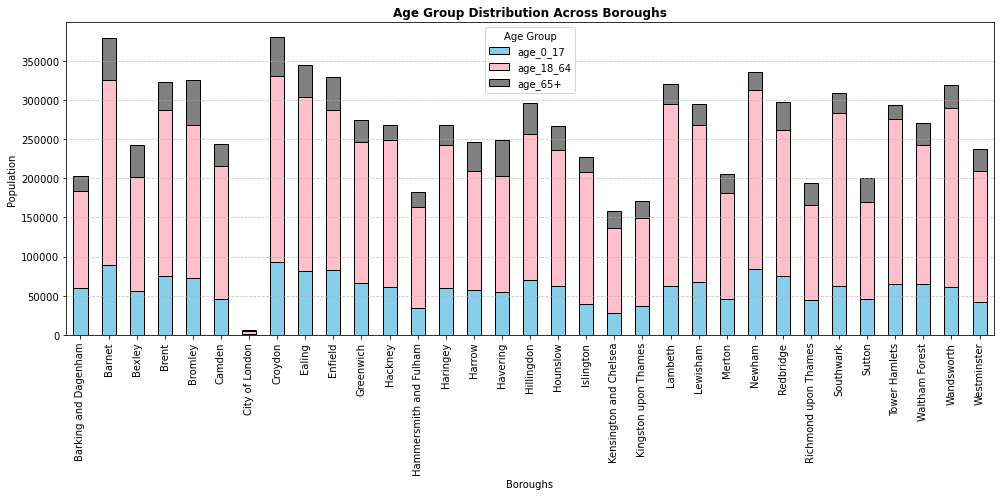

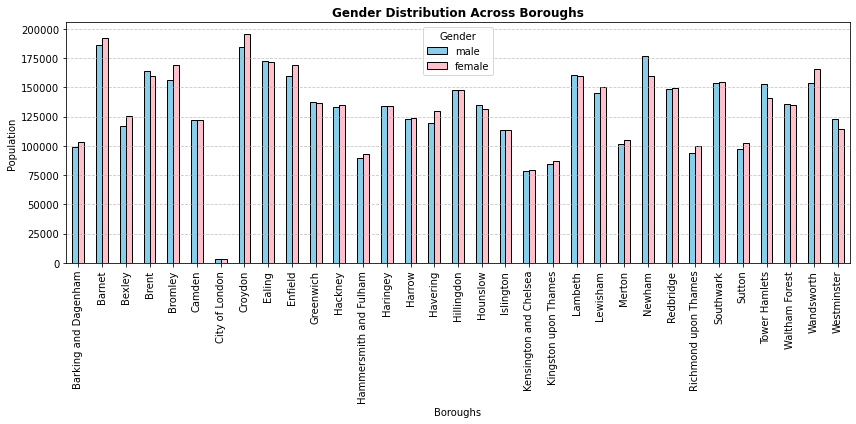

In [4]:
# Compare the age composition of borough populations using stacked bars
age_distribution = annual.set_index(BOROUGH)[["age_0_17", "age_18_64", "age_65+"]].sort_index()

age_distribution.plot(kind="bar", stacked=True, figsize=(14, 7), color=['skyblue', 'pink','grey'], edgecolor="black")

plt.xlabel("Boroughs")
plt.ylabel("Population")
plt.title("Age Group Distribution Across Boroughs",fontweight="bold")
plt.xticks(rotation=90)
plt.legend(title="Age Group")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


# Compare recorded male and female population counts across boroughs
gender_distribution = annual.set_index(BOROUGH)[["male", "female"]].sort_index()

gender_distribution.plot(kind="bar", figsize=(12, 6), color=['skyblue', 'pink'], edgecolor="black")

plt.xlabel("Boroughs")
plt.ylabel("Population")
plt.title("Gender Distribution Across Boroughs", fontweight="bold")
plt.xticks(rotation=90)
plt.legend(title="Gender")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [6]:
# Estimate annual category counts using purchasing shares and recorded product counts
category_sales = annual[CATEGORIES].multiply(annual["num_transactions"], axis=0).sum()

# Identify the categories with the largest and smallest estimated annual counts
print("Most purchased:", category_sales.idxmax())
print("Least purchased:", category_sales.idxmin())

Most purchased: f_fruit_veg
Least purchased: f_spirits


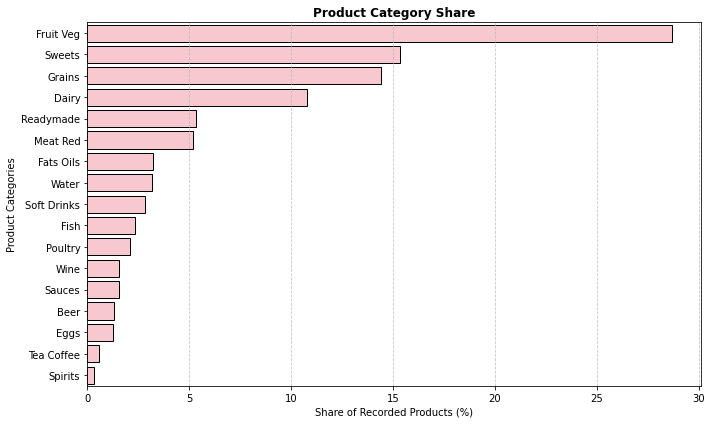

In [7]:
# Sum recorded product counts across boroughs to obtain the denominator
total_transactions = annual['num_transactions'].sum()

category_sales_percentage = (category_sales / total_transactions) * 100

category_sales_percentage_sorted = category_sales_percentage.sort_values(ascending=False)
category_sales_percentage_sorted.index = category_sales_percentage_sorted.index.str.replace("f_", "").str.replace("_", " ").str.title()

# Plot category shares
plt.figure(figsize=(10, 6))
sns.barplot(x=category_sales_percentage_sorted.values, y=category_sales_percentage_sorted.index, color="pink", edgecolor="black")
plt.xlabel("Share of Recorded Products (%)")
plt.ylabel("Product Categories")
plt.title("Product Category Share",fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Fruit and vegetables make up the largest share of recorded products, while spirits account for the smallest. The product mix provides a starting point for assortment planning.

### Relationships between product categories

In [8]:
# Pearson correlation is calculated across all 396 borough-month 
# observations to explore whether purchasing shares vary together. 
# These are descriptive associations; 
# repeated observations within a borough are not independent.

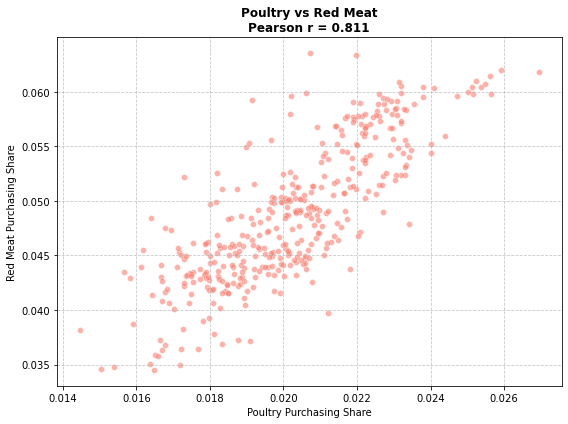

In [9]:
# Compare poultry and red meat shares across borough-month observations
plt.figure(figsize=(8, 6))
sns.scatterplot(x='f_poultry', y='f_meat_red', data=dfs, color="salmon",
    alpha=0.6)
plt.title(f"Poultry vs Red Meat\nPearson r = {dfs['f_poultry'].corr(dfs['f_meat_red']):.3f}",
    fontweight="bold"
)
plt.xlabel('Poultry Purchasing Share')
plt.ylabel('Red Meat Purchasing Share')
plt.grid( linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

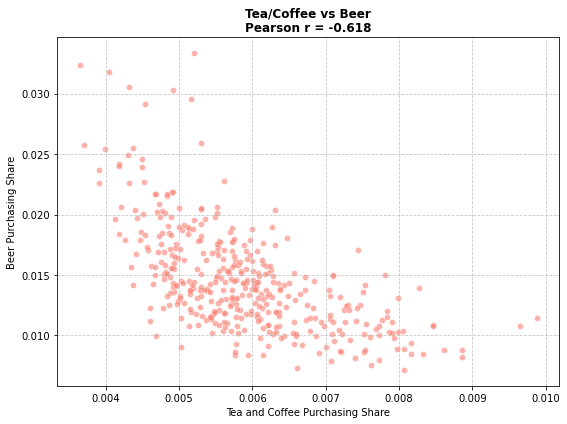

In [10]:
# Examine whether beer and tea/coffee purchasing shares vary together
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=dfs,
    x="f_tea_coffee",
    y="f_beer",
    color="salmon",
    alpha=0.6
)

plt.xlabel("Tea and Coffee Purchasing Share")
plt.ylabel("Beer Purchasing Share")
plt.title(
    f'Tea/Coffee vs Beer\nPearson r = {dfs["f_tea_coffee"].corr(dfs["f_beer"]):.3f}',
    fontweight="bold"
)
plt.grid(linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Poultry and red meat shares are positively correlated, while beer and tea/coffee shares are negatively correlated. These relationships may reflect differences in seasonal and regional purchasing preferences.

## Seasonal purchasing patterns

Monthly recorded counts show how overall purchasing activity changes throughout the year. For individual categories, the mean purchasing share across boroughs is used to compare seasonal patterns independently of overall purchase volume.

In [11]:
# Sum recorded product counts across boroughs for each month
# Calculate unweighted borough-level means to compare monthly purchasing shares
monthly_trends = dfs.groupby('month')['num_transactions'].sum().reindex(MONTHS).reset_index()
monthly_means = dfs.groupby('month')[CATEGORIES + NUTRIENTS].mean().reindex(MONTHS)
# Monthly shares and nutrition indicators are equally weighted across boroughs

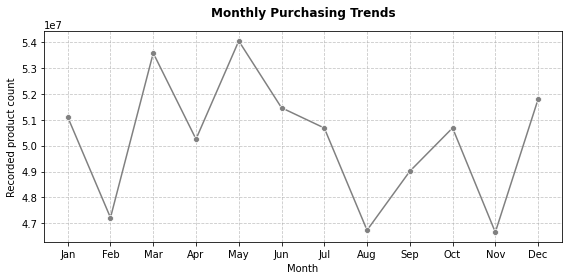

In [12]:
# Visualise overall recorded purchasing activity in calendar order
plt.figure(figsize=(8, 4)) 
sns.lineplot(x='month', y='num_transactions', data=monthly_trends, marker = 'o', color='gray')
plt.xlabel('Month')
plt.ylabel('Recorded product count')
plt.title('Monthly Purchasing Trends', fontweight="bold", pad=15)
plt.xticks()
plt.grid(linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

May recorded the highest overall product count. Monthly totals are affected by the number of days in each month, so this does not necessarily indicate the highest daily purchasing rate.

In [13]:
# Select May observations to examine the product mix in the peak-count month
df_may = dfs[dfs['month'] == "May"]
may_category_sales = df_may[CATEGORIES].multiply(df_may['num_transactions'], axis=0).sum()

# Identify the most and least purchased categories by estimated count
most_sold_may = may_category_sales.idxmax()
least_sold_may = may_category_sales.idxmin()


print("Most purchased category in May:", most_sold_may)
print("Least purchased category in May:", least_sold_may)

Most purchased category in May: f_fruit_veg
Least purchased category in May: f_spirits


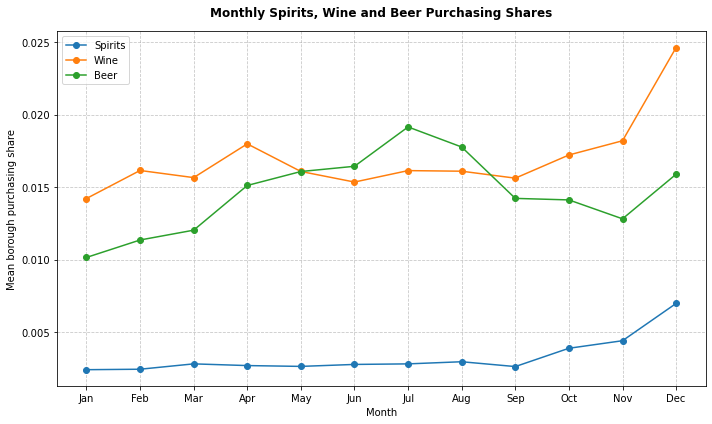

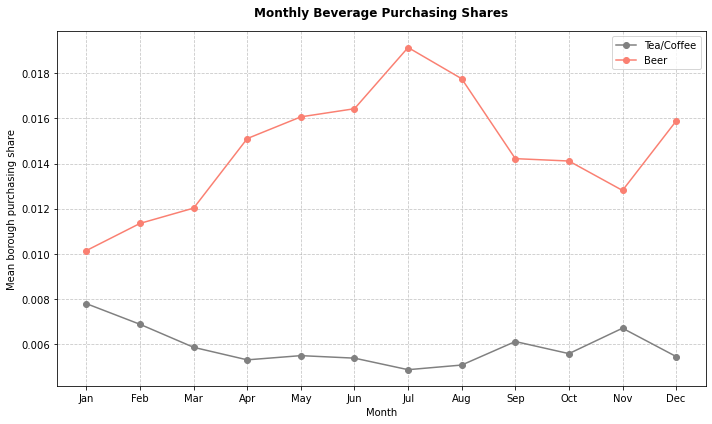

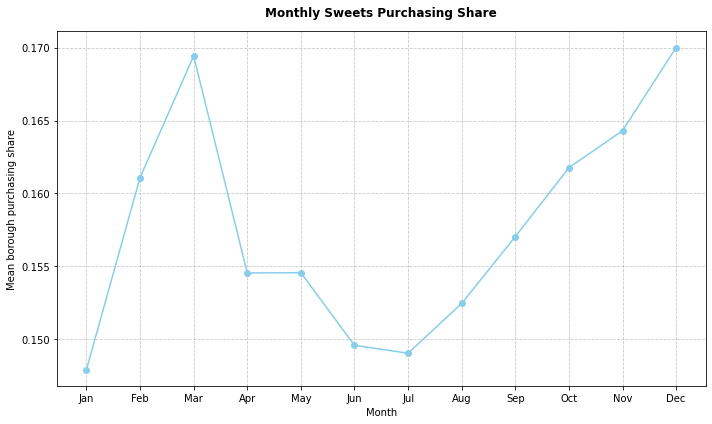

In [14]:
def seasonal_plot(columns, labels, colours, title, ylabel="Mean borough purchasing share"):
    """Plot selected monthly mean indicators using supplied labels and colours."""
    plt.figure(figsize=(10, 6))
    for column, label, colour in zip(columns, labels, colours):
        plt.plot(MONTHS, monthly_means[column], marker="o", color=colour, label=label)
    plt.xlabel("Month")
    plt.ylabel(ylabel)
    plt.title(title, fontweight="bold", pad=15)
    if len(columns) > 1:
        plt.legend()
    plt.grid(linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()

# Compare alcoholic beverages, contrasting beverage categories and sweets
seasonal_plot(["f_spirits","f_wine", "f_beer"], ["Spirits","Wine", "Beer"], ["C0", "C1","C2"], "Monthly Spirits, Wine and Beer Purchasing Shares")
seasonal_plot(["f_tea_coffee", "f_beer"], ["Tea/Coffee", "Beer"], ["grey", "salmon"], "Monthly Beverage Purchasing Shares")
seasonal_plot(["f_sweets"], ["Sweets"], ["skyblue"], "Monthly Sweets Purchasing Share")

In [15]:
# Identify peak months for overall activity and selected beverage shares
print("Highest recorded count:", monthly_trends.loc[monthly_trends["num_transactions"].idxmax(), "month"])
monthly_means[["f_beer", "f_wine", "f_spirits", "f_tea_coffee"]].idxmax().rename("Peak month").to_frame()

Highest recorded count: May


,Peak month
f_beer,Jul
f_wine,Dec
f_spirits,Dec
f_tea_coffee,Jan


Beer purchasing shares rise during summer, contrasting with tea and coffee. Wine and spirits show higher shares in December. These historical patterns could inform the timing of promotions and stock planning.

## Geographical purchasing patterns

Annual purchasing shares are compared across boroughs to explore local product preferences. The monthly data is used to examine how these preferences change over time.

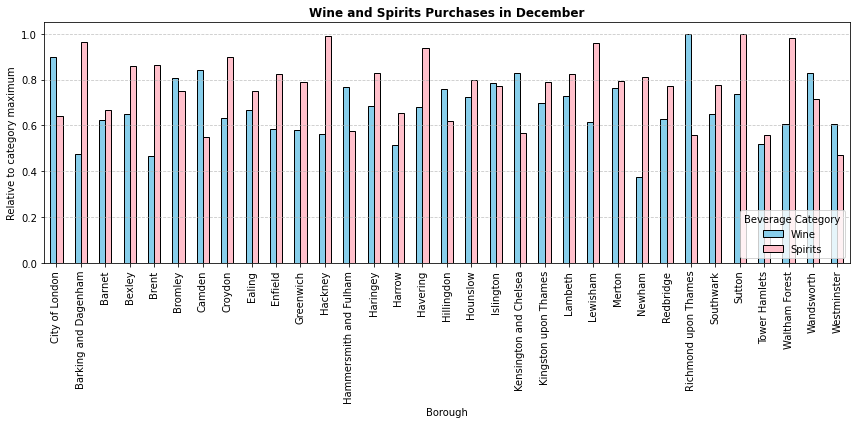

In [16]:
# Select December wine and spirits shares for each borough
december_data = dfs[dfs["month"] == "Dec"].set_index(BOROUGH)[
    ["f_wine", "f_spirits"]
]

# Normalise using each category's maximum across the year
december_data = december_data / dfs[["f_wine", "f_spirits"]].max()

december_data.columns = ["Wine", "Spirits"]

# Compare December shares relative to each category's maximum across the year
december_data.plot(
    kind="bar",
    figsize=(12, 6),
    color=["skyblue", "pink"],
    edgecolor="black"
)

plt.ylabel("Relative to category maximum")
plt.xlabel("Borough")
plt.title("Wine and Spirits Purchases in December", fontweight="bold")
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(title="Beverage Category", loc="lower right")
plt.tight_layout()
plt.show()

### Alcohol purchasing by borough and month

In [17]:
# Select alcohol purchasing indicators for each borough and month
alcohol_data = dfs[[BOROUGH, "month", "f_wine", "f_spirits", "f_beer"]].melt(id_vars=[BOROUGH, "month"], var_name="category", value_name="relative_share")
alcohol_data["category"] = alcohol_data["category"].str.removeprefix("f_").str.title()

# Scale each category against its highest observed purchasing share
# This highlights regional and seasonal variation within each category
alcohol_data["relative_share"] = alcohol_data["relative_share"] / alcohol_data.groupby("category")["relative_share"].transform("max")

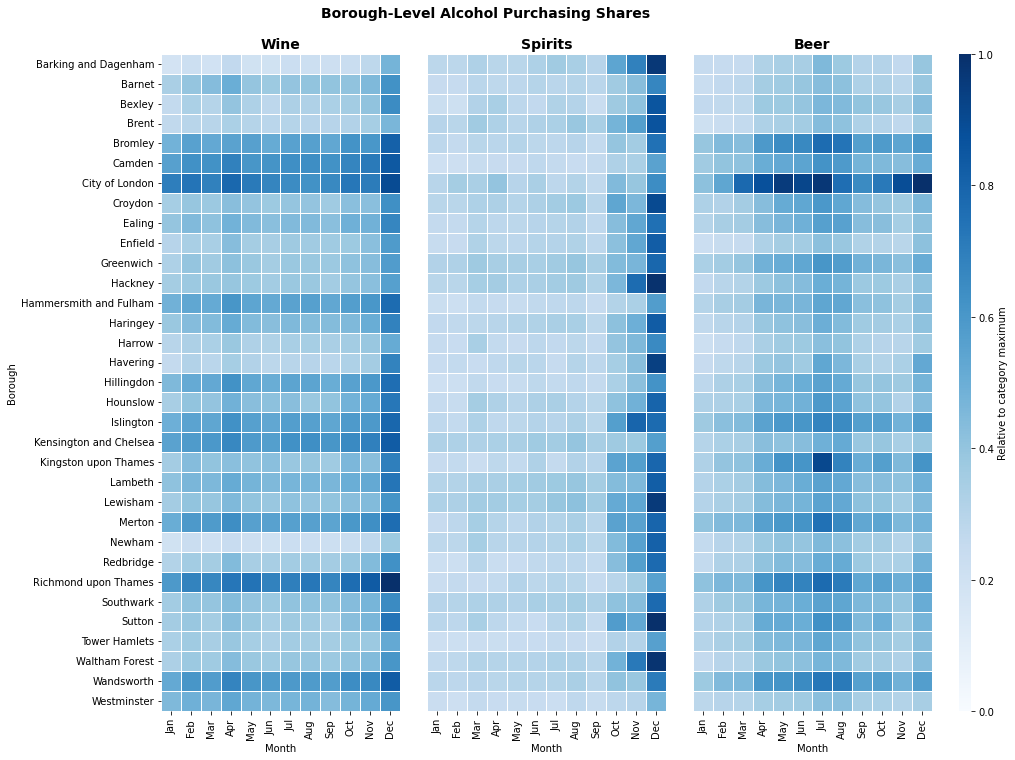

In [18]:
# Create three heatmap panels and a separate axis for a shared colour bar
fig = plt.figure(figsize=(15,11))
gs = gridspec.GridSpec(1,4, width_ratios=[1,1,1,0.05], wspace=0.15)
axes = [fig.add_subplot(gs[i]) for i in range(3)]
cbar_ax = fig.add_subplot(gs[3])

# Plot each alcohol category on the same normalised 0–1 colour scale
for i, (ax, category) in enumerate(zip(axes, ["Wine", "Spirits", "Beer"])):
    table = alcohol_data[alcohol_data["category"] == category].pivot(index=BOROUGH, columns="month", values="relative_share").reindex(columns=MONTHS)
    sns.heatmap(table, cmap="Blues", linewidths=0.5, vmin=0, vmax=1,
                cbar=i==0, cbar_ax=cbar_ax if i==0 else None, ax=ax, yticklabels=i==0)
    ax.set_title(category, fontsize=14, fontweight="bold")
    ax.set_xlabel("Month")
    ax.set_ylabel("Borough" if i==0 else "")
    ax.tick_params(axis="x", rotation=90)
cbar_ax.set_ylabel("Relative to category maximum")
fig.suptitle("Borough-Level Alcohol Purchasing Shares", fontsize=14, fontweight="bold")
fig.subplots_adjust(left=0.20, right=0.95, bottom=0.09, top=0.92)
plt.show()

In [19]:
# Darker cells indicate a higher proportion of purchases belonging to the respective alcohol category, 
# relative to its maximum observed purchasing share across all boroughs and months.

## Conclusion

- Fruit and vegetables account for the largest share of recorded products. 
- Beer purchasing shares increase during summer, while wine and spirits show higher shares in December. The heatmaps also reveal differences in purchasing patterns between boroughs.

### Commercial implications
- Consider festive wine and spirits stock planning and summer beer promotions.
- Explore borough-specific product assortments using local purchasing shares alongside recorded counts.


### Limitations

The data covers 2015 and may not represent current purchasing behaviour. A single year cannot establish recurring seasonal patterns. Tesco Clubcard purchases may not represent the wider population, and borough comparisons are affected by population and retailer coverage. Purchasing shares do not measure revenue or actual consumption.